In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
#Starter-pack class returning aggregated spectral curves from images
class SpectralCurveFiltering():
    """
    Create a histogram (a spectral curve) of a 3D cube, using the merge_function
    to aggregate all pixels within one band. The return array will have
    the shape of [CHANNELS_COUNT]
    """

    def __init__(self, merge_function = np.mean):
        self.merge_function = merge_function

    def __call__(self, sample: np.ndarray):
        return self.merge_function(sample, axis=(1, 2))

In [3]:
gt_path = '../train_data/train_gt.csv'
wl_path = '../train_data/wavelengths.csv'


gt_df = pd.read_csv(gt_path)
wave_lengths = pd.read_csv(wl_path)

In [36]:
#Loading example file, gaining insights about the data

img_no = 1700

path = f'../train_data/train_data/{img_no}.npz'

#axis 0 - band index, 1 - spectral image height, 2 - spectral image width
with np.load(path) as npz:
    spectral_arr = np.ma.MaskedArray(**npz)

bands, height, width = spectral_arr.shape

print(f'Bands = {bands}, height = {height}, width = {width}')
print(f'Data type: {spectral_arr.dtype}')
print(f'Max val = {spectral_arr.max()}, min val = {spectral_arr.min()}')



Bands = 150, height = 96, width = 103
Data type: int16
Max val = 1911, min val = 147


In [ ]:
#Plotting with & without binary mask
fig, ax = plt.subplots(2,2, figsize=(8,8))

ax[0,0].imshow(spectral_arr[0,:,:].data)
ax[0,1].imshow(spectral_arr[0,:,:])

ax[1,0].imshow(spectral_arr[149,:,:].data)
ax[1,1].imshow(spectral_arr[149,:,:])

plt.suptitle(f'Band 0 vs band 149 of spectral image {img_no}.npz')
plt.show()

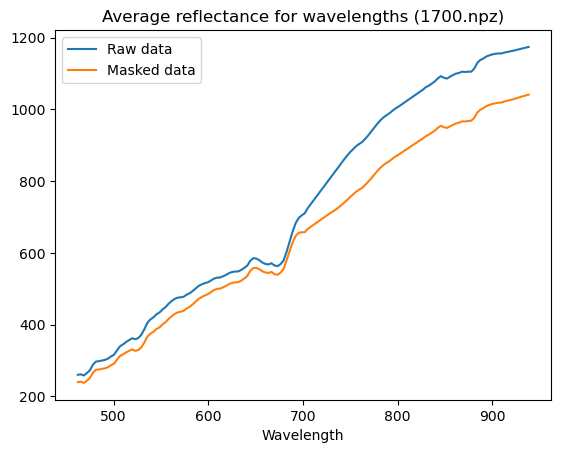

In [37]:
#Plotting spectral reflectance of the example image using SpectralCurveFiltering class
filtering = SpectralCurveFiltering()
spectral_curve = filtering(spectral_arr.data)
masked_curve = filtering(spectral_arr)

plt.plot(wave_lengths['wavelength'], spectral_curve, label = "Raw data")
plt.plot(wave_lengths['wavelength'], masked_curve, label = "Masked data")
plt.title(f'Average reflectance for wavelengths ({img_no}.npz)')
plt.xlabel("Wavelength")
plt.legend()
plt.show()

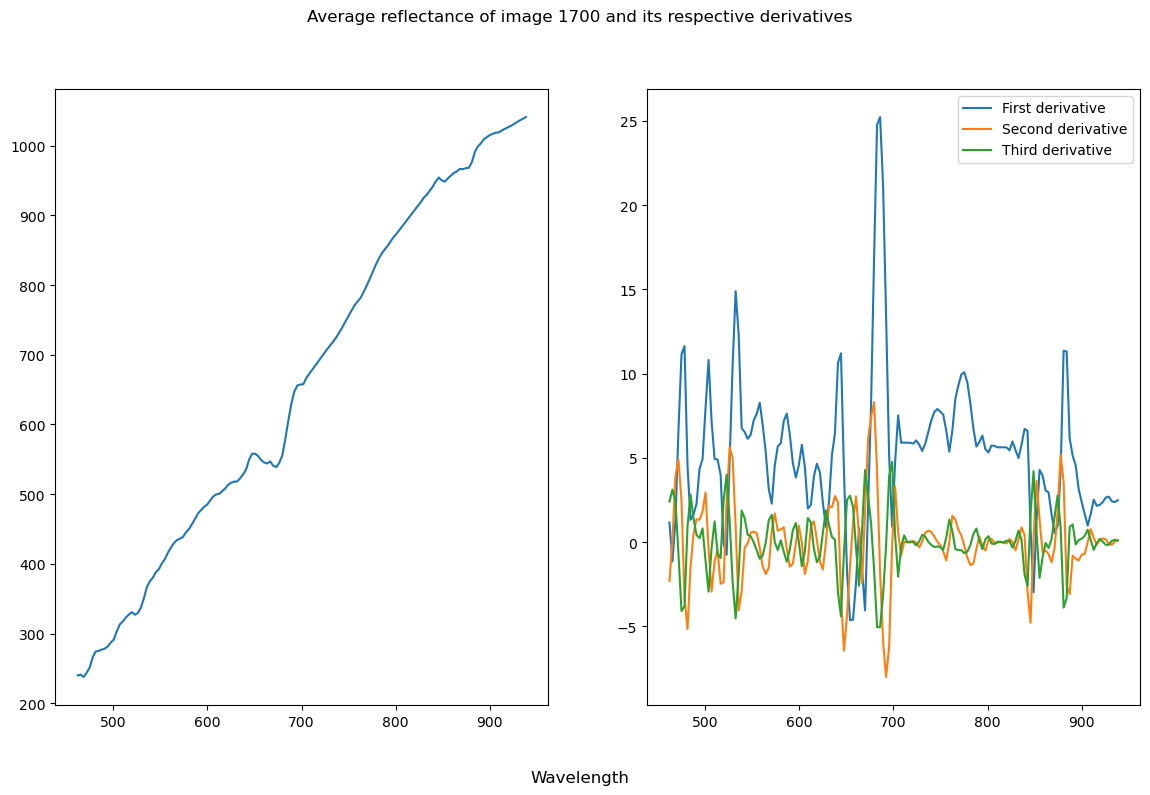

In [51]:
#Calculating and plotting first, second and third order derivatives of avg spectral reflectance curve
first_der = np.gradient(masked_curve, axis=0)
second_der = np.gradient(first_der, axis=0)
third_der = np.gradient(second_der, axis=0)

#plt.plot(wave_lengths['wavelength'], masked_curve, label = "Masked data")
fig, ax = plt.subplots(1, 2, figsize=(14,8))
plt.suptitle(f"Average reflectance of image {img_no} and its respective derivatives")
ax[0].plot(wave_lengths['wavelength'], masked_curve, label = "Masked curve")
ax[1].plot(wave_lengths['wavelength'], first_der, label = "First derivative")
ax[1].plot(wave_lengths['wavelength'], second_der, label = "Second derivative")
ax[1].plot(wave_lengths['wavelength'], third_der, label = "Third derivative")
ax[1].legend()
fig.supxlabel("Wavelength")
plt.show()

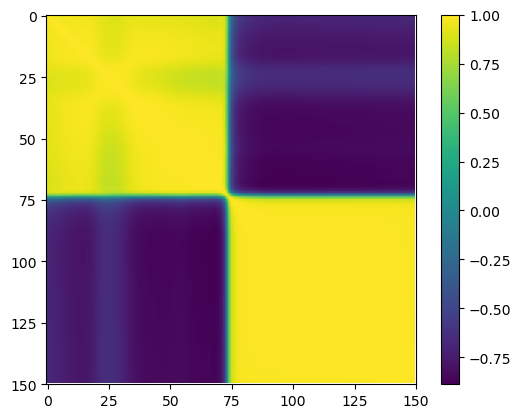

In [8]:
#Calculating correlation between bands of the example image
image_flat = spectral_arr.reshape(bands, -1)
corr = np.corrcoef(image_flat)

plt.imshow(corr, cmap='viridis')
plt.colorbar()
plt.xticks(range(0,bands+1,25))
plt.yticks(range(0,bands+1,25))
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
#Preparing data for PCA (of the example image)
X = spectral_arr.data.reshape(bands, -1).T #(width * height, bands) transposed

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_transformed = pca.fit_transform(X_scaled)

In [ ]:
plt.bar(range(pca.n_components_), pca.explained_variance_ratio_)
plt.xticks(range(pca.n_components_))
plt.yticks(np.arange(0,1.1,0.1))
plt.show()

In [ ]:
#first principal component
pc1 = pca.components_[0]
pc2 = pca.components_[1]

print(pca.components_.shape)

In [ ]:
    #PCA for almost whole dataset (step = 10 - every 10th image)
X_total = []

for i in range(0,1701,1):
    with np.load(f'../train_data/train_data/{i}.npz') as npz:
        arr = np.ma.MaskedArray(**npz)

    x = arr.data.reshape(arr.shape[0], -1).T #(width * height, bands)
    mask = arr.mask.reshape(arr.shape[0], -1).T

    #including binary mask
    x_valid = x[~mask.any(axis=1)]
    X_total.append(x_valid)

X_total = np.vstack(X_total)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_total)

pca = PCA(n_components=10)
X_transformed = pca.fit_transform(X_scaled)

print(pca.explained_variance_ratio_.cumsum())


In [ ]:
#Plotting variance ratios of every Prinicpal Component - there are 2 PC's that explain >= 95% of the data variance
plt.bar(range(pca.n_components_), pca.explained_variance_ratio_)
plt.xticks(range(pca.n_components_))
plt.yticks(np.arange(0,1.1,0.1))
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_pca_loadings(pca_model, wavelengths=None, n_components=3):
    """
    Visualizes PCA loadings (eigenvectors) to show band influence.
    """
    loadings = pca_model.components_

    n_bands = loadings.shape[1]

    if wavelengths is None:
        x_axis = np.arange(n_bands)
        x_label = "Band Index"
    else:
        if len(wavelengths) != n_bands:
            print(f"WARNING: Length of wavelengths list ({len(wavelengths)}) does not match number of bands in PCA ({n_bands}). Using indices.")
            x_axis = np.arange(n_bands)
            x_label = "Band Index"
        else:
            x_axis = wavelengths
            x_label = "Wavelength [nm]"

    plt.figure(figsize=(14, 6))

    colors = ['blue', 'orange', 'green', 'red', 'purple']

    for i in range(n_components):
        c = colors[i % len(colors)]
        plt.plot(x_axis, loadings[i, :], label=f'PC {i+1}', color=c, linewidth=1.5)

        max_idx = np.argmax(np.abs(loadings[i, :]))
        plt.scatter(x_axis[max_idx], loadings[i, max_idx], color=c, s=50, zorder=5)

    plt.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)

    plt.title(f'PCA Loadings: Band Influence on First {n_components} Components', fontsize=14)
    plt.xlabel(x_label, fontsize=12)
    plt.ylabel('Loading Value (Eigenvector Coefficient)', fontsize=12)
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
plot_pca_loadings(pca, wavelengths=None, n_components=4)

Calculating avarage spectrum for each image

In [14]:
X_means = []
valid_indices = []


for idx, row in gt_df.iterrows():
    img_id = int(row.get('sample_index', idx))

    path = f'../train_data/train_data/{img_id}.npz'

    try:
        with np.load(path) as npz:
            arr = np.ma.MaskedArray(**npz)
        mean_spectrum = arr.mean(axis=(1,2))
        if np.ma.is_masked(mean_spectrum):
            continue
        X_means.append(mean_spectrum.data)
        valid_indices.append(idx)

    except FileNotFoundError:
        print(f"File not found for index {img_id}")
        continue

X_means = np.array(X_means)
gt_df_clean = gt_df.loc[valid_indices].reset_index(drop=True)
print({X_means.shape})
print( {len(gt_df_clean)})

KeyboardInterrupt: 

In [15]:
target_cols = ['P', 'K', 'Mg', 'pH']
if 'wave_lengths' in locals():
    wl_axis = wave_lengths['wavelength'].values
    index_name = 'Wavelength [nm]'
else:
    wl_axis = np.arange(X_means.shape[1])
    index_name = 'Band Index'
correlations = {col: [] for col in target_cols}
for band_idx in range(X_means.shape[1]):
    band_vals = X_means[:, band_idx]

    for target in target_cols:
        if target not in gt_df_clean.columns:
            continue

        y_vals = gt_df_clean[target].values
        if np.std(band_vals) == 0 or np.std(y_vals) == 0:
            corr = 0 #
        else:
            corr = np.corrcoef(band_vals, y_vals)[0, 1]
        correlations[target].append(corr)


In [16]:
feature_corr_matrix = gt_df_clean[target_cols].corr()
print(feature_corr_matrix)

           P         K        Mg        pH
P   1.000000  0.413494 -0.103034  0.120067
K   0.413494  1.000000  0.234162  0.168793
Mg -0.103034  0.234162  1.000000  0.010980
pH  0.120067  0.168793  0.010980  1.000000


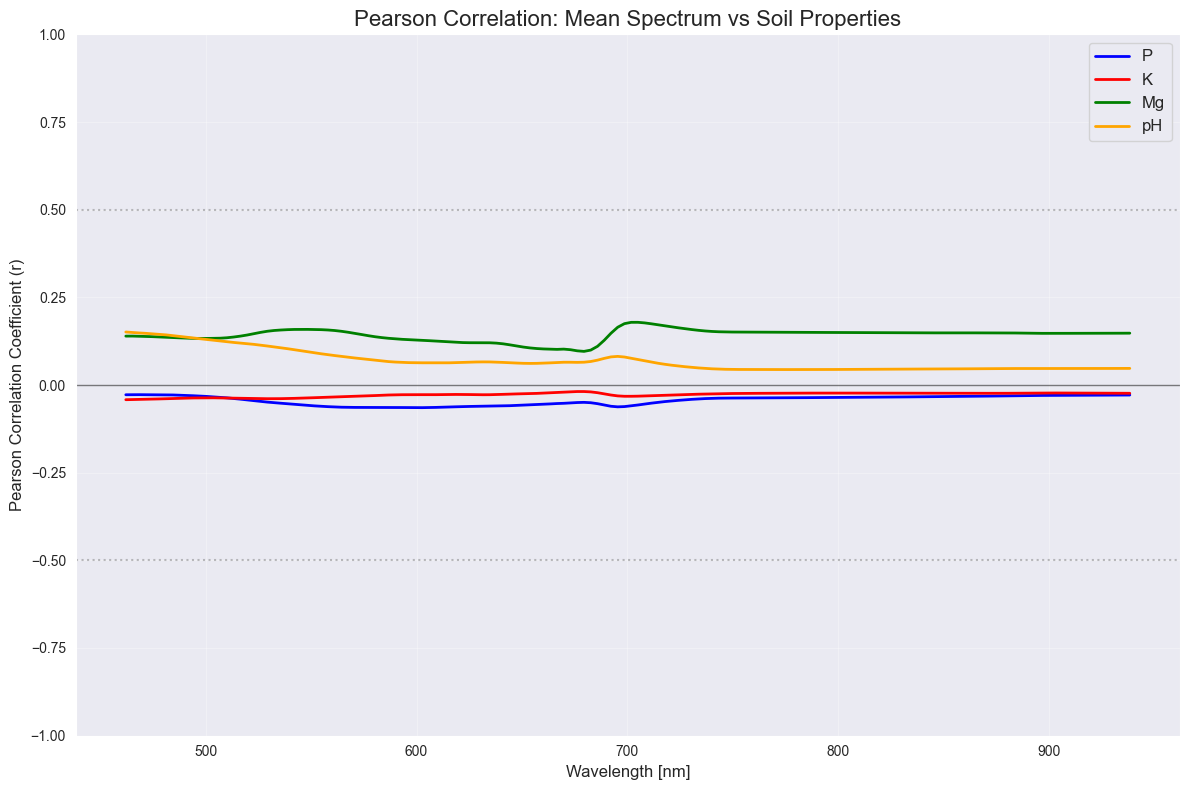

In [18]:
plt.figure(figsize=(12, 8))

colors = ['blue', 'red', 'green', 'orange', 'purple', 'brown']

for i, target in enumerate(target_cols):
    if target in correlations and len(correlations[target]) > 0:


        current_color = colors[i % len(colors)]

        plt.plot(wl_axis, correlations[target], label=target, color=current_color, linewidth=2)

plt.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.5)
plt.axhline(0.5, color='gray', linestyle=':', alpha=0.5)
plt.axhline(-0.5, color='gray', linestyle=':', alpha=0.5)

plt.title('Pearson Correlation: Mean Spectrum vs Soil Properties', fontsize=16)
plt.xlabel('Wavelength [nm]', fontsize=12)
plt.ylabel('Pearson Correlation Coefficient (r)', fontsize=12)
plt.legend(fontsize=12, loc='upper right')
plt.grid(True, alpha=0.3)

plt.ylim(-1.0, 1.0)
plt.tight_layout()
plt.show()